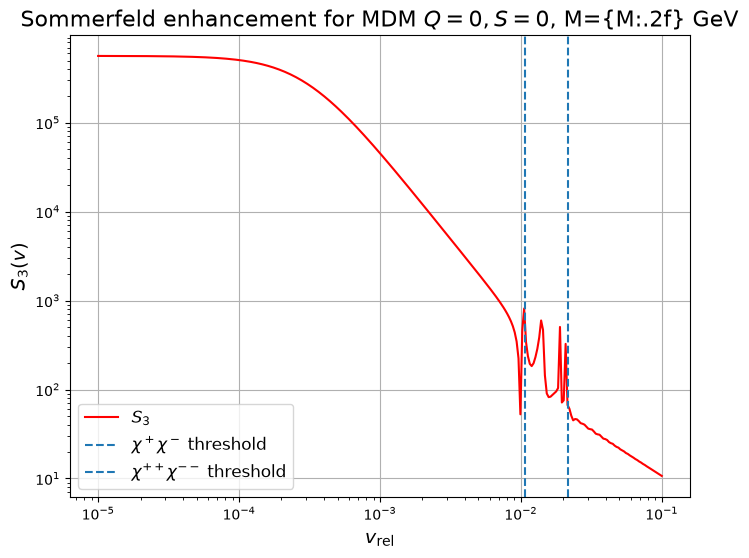

In [ ]:
import numpy as np
from sommerfeld_mdm.sommerfeld import sommerfeld
from sommerfeld_mdm.mdm import mdm_quintupletQ0S0
import matplotlib.pyplot as plt

M = 11500.0
delta = 0.167
Mw = 80.379

Tstart = 200
vstart = min(np.sqrt( ( 6 * Tstart ) / M),0.5)
V_inf, V_eff, Gamma = mdm_quintupletQ0S0(M)
v_rel = np.logspace(-5, np.log10(0.1), 300)
S3_list = []

for v in v_rel:
    p = M * v / 2
    x_inf = 10.0 * p / Mw

    T = sommerfeld(
        M=M,
        v_rel=v,
        V_inf=V_inf,
        V_eff=V_eff,
        x_inf=x_inf 
    )
    T_conj = T.conj().T

    S3 = (
        (T_conj @ Gamma @ T)[2, 2].real
        / Gamma[2, 2]
    )

    S3_list.append(S3)

S3_list = np.array(S3_list)

v_threshold_2 = np.sqrt(8 * delta / M)
v_threshold_1 = np.sqrt(32 * delta / M)

plt.figure(figsize=(8,6))
plt.loglog(v_rel, S3_list, label=r"$S_3$", color="red")
plt.axvline(v_threshold_2, linestyle="--",label=r"$\chi^+\chi^-$ threshold")
plt.axvline(v_threshold_1, linestyle="--",label=r"$\chi^{++}\chi^{--}$ threshold")
plt.xlabel(r"$v_\mathrm{rel}$", fontsize=14)
plt.ylabel(r"$S_3(v)$", fontsize=14)
plt.title(f"Sommerfeld enhancement for MDM $Q=0, S=0$, M={M:.2f} GeV", fontsize=16)
plt.legend(fontsize=12)
plt.grid()
plt.show()  


In [ ]:
print(v_threshold_2, v_threshold_1)
T_threshold_2 = M * (v_threshold_2)**2 / 6
T_threshold_1 = M * (v_threshold_1)**2 / 6
print(T_threshold_2, T_threshold_1)



0.010778400300762552 0.021556800601525105
0.2226666666666667 0.8906666666666668


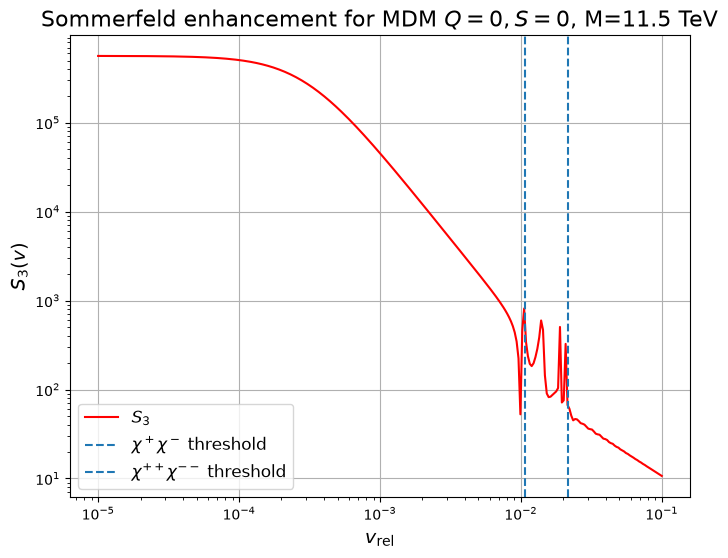

In [9]:
plt.figure(figsize=(8,6))
plt.loglog(v_rel, S3_list, label=r"$S_3$", color="red")
plt.axvline(v_threshold_2, linestyle="--",label=r"$\chi^+\chi^-$ threshold")
plt.axvline(v_threshold_1, linestyle="--",label=r"$\chi^{++}\chi^{--}$ threshold")
plt.xlabel(r"$v_\mathrm{rel}$", fontsize=14)
plt.ylabel(r"$S_3(v)$", fontsize=14)
plt.title(f"Sommerfeld enhancement for MDM $Q=0, S=0$, M={M/1000:.1f} TeV", fontsize=16)
plt.legend(fontsize=12)
plt.grid()
plt.show() 

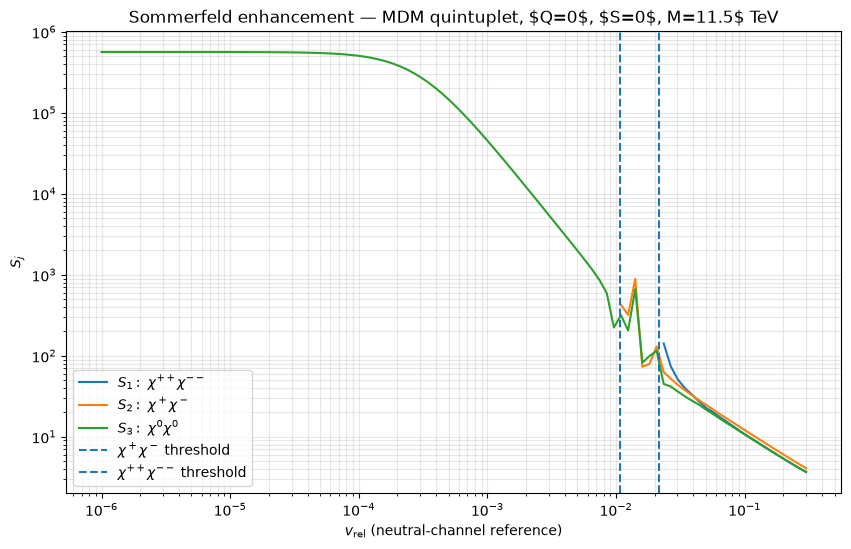

In [10]:
M = 11500
delta = 0.167
Mw = 80.379
V_inf, V_eff, Gamma = mdm_quintupletQ0S0(M)

def sommerfeld_factors(v_rel, x_inf=30.0):

    E = M * (v_rel / 2)**2

    # Indices of kinematically open incoming channels
    open_idx = np.flatnonzero(E > np.diag(V_inf))

    T = sommerfeld(
        M=M,
        v_rel=v_rel,
        V_inf=V_inf,
        V_eff=V_eff,
        x_inf=x_inf
    )

    # Accept both compact and padded T matrices
    if T.shape[1] == len(open_idx):
        T_open = T
    elif T.shape[1] == 3:
        T_open = T[:, open_idx]
    else:
        raise ValueError(f"Unexpected T shape: {T.shape}")

    # Sommerfeld-corrected annihilation matrix
    Gamma_SE = T_open.conj().T @ Gamma @ T_open

    # Undefined for closed incoming channels
    S = np.full(3, np.nan)

    S[open_idx] = (
        np.diag(Gamma_SE).real
        / np.diag(Gamma)[open_idx]
    )

    return S

velocities = np.geomspace(1e-6, 0.3, 100)

S_values = np.array([
    sommerfeld_factors(v_rel , x_inf = 10.0 * (M * v_rel / 2) / Mw)
    for v_rel in velocities
])

S1 = S_values[:, 0]
S2 = S_values[:, 1]
S3 = S_values[:, 2]

v_th_2 = np.sqrt(8 * delta / M)
v_th_1 = np.sqrt(32 * delta / M)

plt.figure(figsize=(10, 6))

plt.loglog(
    velocities, S1,
    label=r"$S_1:\ \chi^{++}\chi^{--}$"
)

plt.loglog(
    velocities, S2,
    label=r"$S_2:\ \chi^+\chi^-$"
)

plt.loglog(
    velocities, S3,
    label=r"$S_3:\ \chi^0\chi^0$"
)

plt.axvline(
    v_th_2,
    linestyle="--",
    label=r"$\chi^+\chi^-$ threshold"
)

plt.axvline(
    v_th_1,
    linestyle="--",
    label=r"$\chi^{++}\chi^{--}$ threshold"
)

plt.xlabel(r"$v_{\mathrm{rel}}$ (neutral-channel reference)")
plt.ylabel(r"$S_j$")
plt.title(f"Sommerfeld enhancement — MDM quintuplet, $Q=0$, $S=0$, M={M/1000:.1f}$ TeV")

plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()